In [1]:
import pandas as pd

url = "http://byungwan.com/class/House_Prices.xls"
house = pd.read_excel(url)

house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood
0,1,114300,1790,2,2,2,No,East
1,2,114200,2030,4,2,3,No,East
2,3,114800,1740,3,2,1,No,East
3,4,94700,1980,3,2,3,No,East
4,5,119800,2130,3,3,3,No,East


In [3]:
house["House_Class"] = pd.qcut(house["Price"], 2, labels=[0,1])

In [4]:
house.head(2)

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,Brick,Neighborhood,House_Class
0,1,114300,1790,2,2,2,No,East,0
1,2,114200,2030,4,2,3,No,East,0


In [5]:
house = pd.get_dummies(house, columns=["Brick", "Neighborhood"], drop_first=True, dtype=int)

In [6]:
house.head()

,HomeID,Price,SqFt,Bedrooms,Bathrooms,Offers,House_Class,Brick_Yes,Neighborhood_North,Neighborhood_West
0,1,114300,1790,2,2,2,0,0,0,0
1,2,114200,2030,4,2,3,0,0,0,0
2,3,114800,1740,3,2,1,0,0,0,0
3,4,94700,1980,3,2,3,0,0,0,0
4,5,119800,2130,3,3,3,0,0,0,0


In [10]:
from sklearn.model_selection import train_test_split

y = house.iloc[:, 6]
x = house.iloc[:, [2,3,4,5,7,8,9]]

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0) # "test_size = 0.3" = 70% for training, and 30% for testing

## Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=5, random_state=0, max_depth=3) # n_estimators = no. of trees

In [41]:
rfc_model = rfc.fit(x_train, y_train)

In [42]:
y_pred = rfc_model.predict(x_test)

In [43]:
from sklearn import metrics

metrics.accuracy_score(y_test, y_pred)

0.7692307692307693

## Visualization

In [44]:
tree0 = rfc_model.estimators_[0] # among 5 trees we have, [0] is the first tree

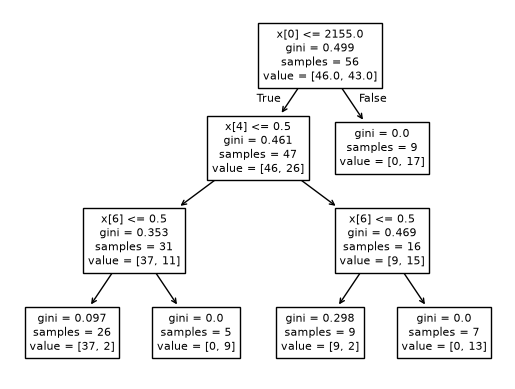

In [45]:
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree

plot_tree(tree0)
plt.show()

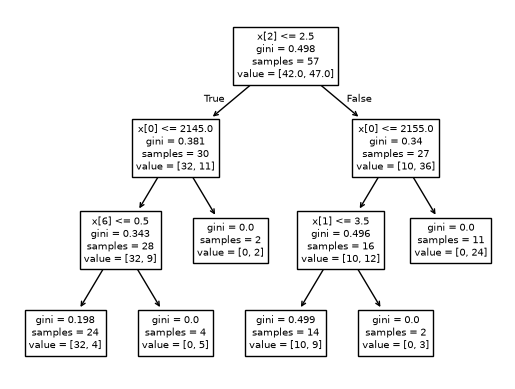

In [46]:
tree1 = rfc_model.estimators_[1]

plot_tree(tree1)
plt.show()

## Feature Importance

In [29]:
fi = rfc_model.feature_importances_
fi

array([0.24591346, 0.06596447, 0.15233753, 0.05207958, 0.05979063,
       0.10303272, 0.32088161])

In [26]:
x.columns.tolist()

['SqFt',
 'Bedrooms',
 'Bathrooms',
 'Offers',
 'Brick_Yes',
 'Neighborhood_North',
 'Neighborhood_West']

In [30]:
pd.DataFrame({"Variable": x.columns.tolist(), "Feature Importance": fi}) 

,Variable,Feature Importance
0,SqFt,0.245913
1,Bedrooms,0.065964
2,Bathrooms,0.152338
3,Offers,0.052080
4,Brick_Yes,0.059791
5,Neighborhood_North,0.103033
6,Neighborhood_West,0.320882


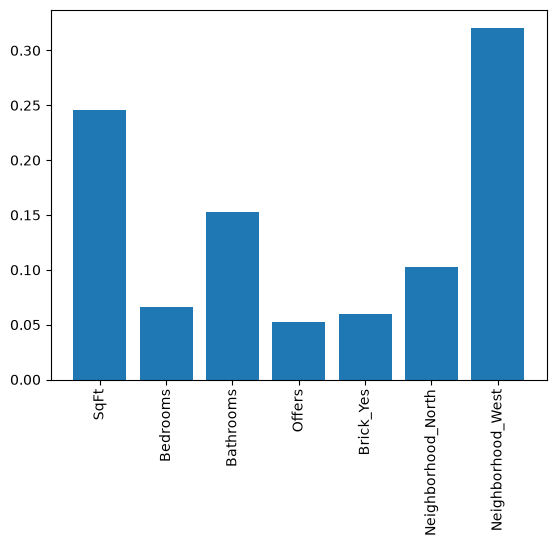

In [33]:
plt.bar(x.columns.tolist(), fi)
plt.xticks(rotation=90)
plt.show()

## Shapley Values

In [34]:
!pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 13.5 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [35]:
import shap

In [36]:
explainer = shap.TreeExplainer(rfc_model)

In [37]:
shap_exp = explainer(x_test)

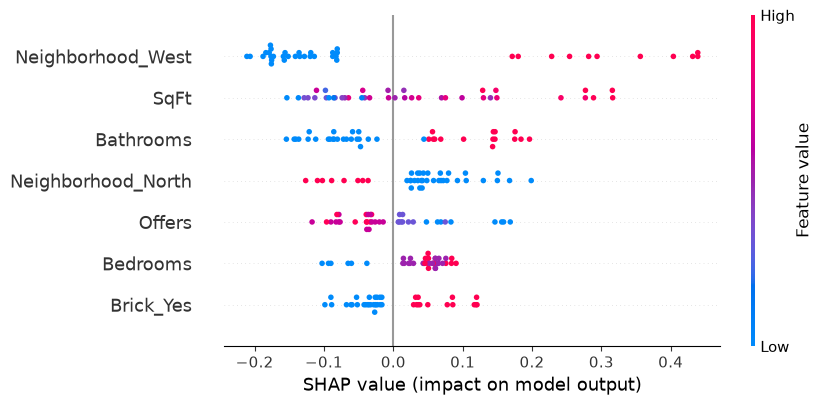

In [39]:
shap.plots.beeswarm(shap_exp[:, :, 1])